# Lab 6 - Variable selection

In this lab we consider the variable selection problem in (supervised) classification.

In [1]:
import numpy as np
import matplotlib.pyplot as plt

### Data generation

To generate a synthetic dataset suitable for variable selection, we first generate a subset of _relevant_ features, and then add a second set of _irrelevant_ (or dummy) featuers. We proceed as follows:
- Generate a dataset with the `mixGauss` function: use two Gaussians which are *close* to each other. Start by considering 2-dimensional points.
- Plot the points: you should observe two point-clouds which mix with each other (since they were generated with the same parameters).
- Enrich the input samples with "dummy" features randomly sampled and add them to the relevant features (notice that at this point data visualization is no longer possible since we are in more than 2 dimensions).


In [2]:
def mixGauss(means, sigmas, n):
    means = np.array(means)
    sigmas = np.array(sigmas)

    d = means.shape[1]
    num_classes = sigmas.size
    data = np.full((n * num_classes, d), np.inf)
    labels = np.zeros(n * num_classes)

    for idx in range(len(sigmas)):
        data[idx * n:(idx + 1) * n] = np.random.multivariate_normal(mean=means[idx],
                                            cov=np.eye(d) * sigmas[idx] ** 2, size=n)
        labels[idx * n:(idx + 1) * n] = idx

    if(num_classes == 2):
        labels[labels==0] = -1

    return data, labels

(2000, 2) (2000,)


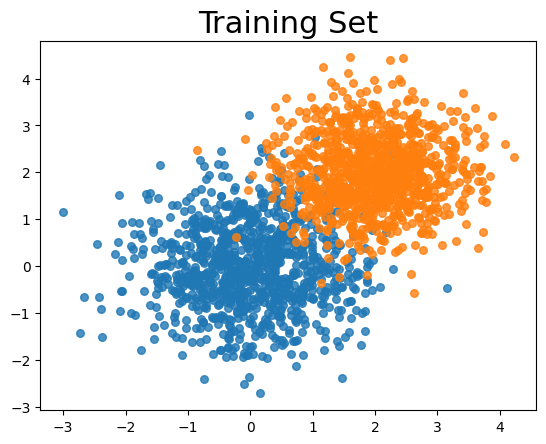

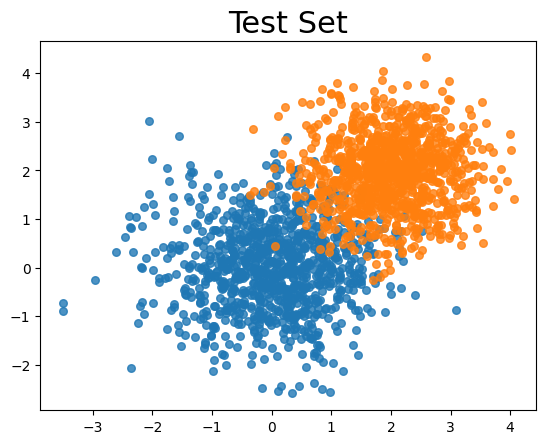

In [3]:
n = 1000 # number of data points for each gaussian
d = 30 # total number of features
d_rel = 2 # number of relevant features

Xtr, Ytr = mixGauss(means = [[0,0],[2,2]], sigmas = [0.9, 0.75], n=n)
Xte, Yte = mixGauss(means = [[0,0],[2,2]], sigmas = [0.9, 0.75], n=n)

# plot
fig, ax = plt.subplots()
ax.set_title("Training Set", fontsize=22)
ax.scatter(Xtr[Ytr==-1,0], Xtr[Ytr==-1,1], s=30, alpha=0.80) #le Xtr che hanno etichetta -1 appartenenti alla prima e seconda variabile
ax.scatter(Xtr[Ytr==1,0], Xtr[Ytr==1,1],s=30, alpha=0.80) #le Xtr che hanno etichetta 1 appartenenti alla prima e seconda variabile

fig, ax = plt.subplots()
ax.set_title("Test Set", fontsize=22)
ax.scatter(Xte[Yte==-1,0], Xte[Yte==-1,1], s=30, alpha=0.80)
ax.scatter(Xte[Yte==1,0], Xte[Yte==1,1], s=30, alpha=0.80)

print(Xtr.shape , Ytr.shape)

In [4]:
# Dummy features generation
sigma_noise = 0.13
Xtr_noise = sigma_noise * np.random.randn(2*n, d-d_rel)
Xtr = np.concatenate((Xtr,Xtr_noise), axis=1)           #concateno 28 feature irrelevanti
Xte_noise = sigma_noise * np.random.randn(2*n, d-d_rel) #np.random.radn = genera numeri casuali estratti da una distribuzione normale standard , in questo caso una matrice di dimensione 2*n (=2000) X d-d_rel (=28)
Xte = np.concatenate((Xte,Xte_noise), axis=1)           # concatena di fianco a Xtr e Xte

print(Xtr.shape, Xte.shape)

#stabilire quali feature interessano di più , selezione di feature più importanti, metto dei coefficenti su feature più imortanti e pongo 0 i coefficenti per le altre feature.
#esempio casa : devo trovare casa migliore da comprare , ho tante feature : posizione casa, prezzo, zona, ecc..., il nostro scopo è selezionare le feature più importanti per la nostra scelta,
#se non mi piacciono le case a cian de dria le escludo a priori assegnadole un peso nullo, in base a ciò che mi piace assegno pesi diversi.
#algoritmo è greedy scelgo la seconda migliore in funzione della scelta dell'iterazione prima
#l'iterazione alla quale ci fermiamo indica quante feature abbiamo deciso di considerare .
#al di là del ML : ho un sistema lineare sovraparmetrizzato , inifinite soluz, cosa ci dice feature selection: tra le tante ,infinte, soluzioni , se ho l'informazione che la soluzione che cerco è sparsa ,
#(ha tanti zeri ,pochi elementi non nulli) => posso trovare la soluzione desiderata

(2000, 30) (2000, 30)


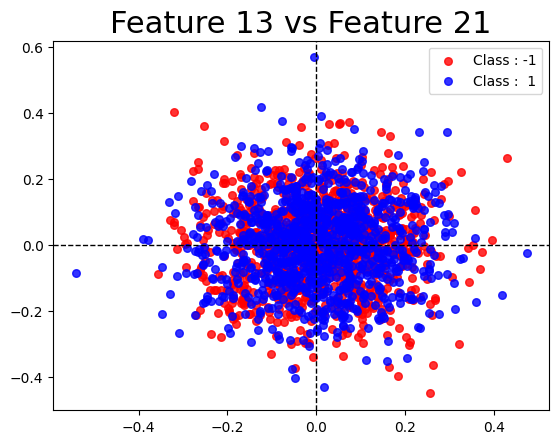

In [5]:
fig, ax = plt.subplots()
ax.set_title("Feature 13 vs Feature 21", fontsize=22)
ax.scatter(Xtr[Ytr==-1,12], Xtr[Ytr==-1,20], color='red' , s=30, alpha=0.80)
ax.scatter(Xtr[Ytr==1,12], Xtr[Ytr==1,20],color='blue' , s=30, alpha=0.80)
ax.axhline(0, color='black', linestyle='--', linewidth=1)
ax.axvline(0, color='black', linestyle='--', linewidth=1)
ax.legend(fontsize=10, loc='best', labels=['Class : -1', 'Class :  1'])

#fa vedere che pur avendo valori uguali delle feature 10 e 11 hanno però etichette diverse!
#ma così vale per ogni altra variabile fittizia

## Variable selection

We will now define a function that implements the Orthogonal Matching Pursuit (OMP) algorithm. This algorithm computes a sparse representation of a signal.

The function has the following signature:
    
`w, r, I = OMP(X, Y, iters)`

where:

*   `X`: input data
*   `Y`: output labels
*   `iters`: number of iterations


*   `w`: estimated coefficients
*   `r`: residuals
*   `I`: indices


In [6]:
def OMP(X, Y, iters):
    # Extract number of data points and dimensions from the shape of the input X
    N, D = np.shape(X)

    # Initialization of residual, coefficient vector and index list I
    r = Y
    w = np.zeros(D)
    I = []

    # Initialize a temporary list of indexes for all the dimensions D
    J_tmp = list(range(D))

    # For each iteration
    for i in range(iters):
        # 1. Select the index which coefficient most "explains" the residual
        # Initialize the maximal residual component a_max to an arbitrary negative number
        a_max = -1

        # For every index j in J_tmp
        for j in J_tmp:
            # Compute the residual component
            a_tmp = (np.dot(X[:, j], r.T))**2/np.linalg.norm(X[:, j])**2

            # Update the maximal residual component and the corresponding index
            if a_tmp > a_max:
                a_max = a_tmp
                j_max = j

        # Add the index corresponding to the maximal residual component to the list of indexes I
        I.append(j_max)

        # And update the temporary list J_tmp by removing this index
        J_tmp.remove(j_max)

        # 2. Update the estimated coefficients
        # Compute the M matrix
        M_I = np.zeros((D, D))
        for j in I:
            M_I[j, j] = 1 #matrice di maskin , diagonale 1 se appartiene all'active set , 0 altrimenti


        # Compute the weight vector
        A = M_I.T @ X.T @ X @ M_I
        B = M_I.T @ X.T @ Y         # è un vettore! dx1
        w = np.linalg.pinv(A) @ B

        # 3. Update the residual
        r = Y - np.dot(X,w)

    return w, r, I

We now need a  function to compute the percentage error in the predicted labels (remember that we are dealing with _binary_ classification):

In [7]:
def calcError(Ypred, Y):
    return np.mean(np.sign(Ypred) != Y) * 100

We are now ready to run the Orthogonal Matching Pursuit algorithm. Proceed as follows:

1. Standardize the data,
2. Manually choose a number of iterations `iters` and run OMP on the training set,
3. Compute the prediction on the test set and evaluate the error,
4. Plot the components of the solution `w` (considering their absolute value), how do they look?

I: [86, 4]
Test Error : 19.75%


Text(0, 0.5, '$|w|$')

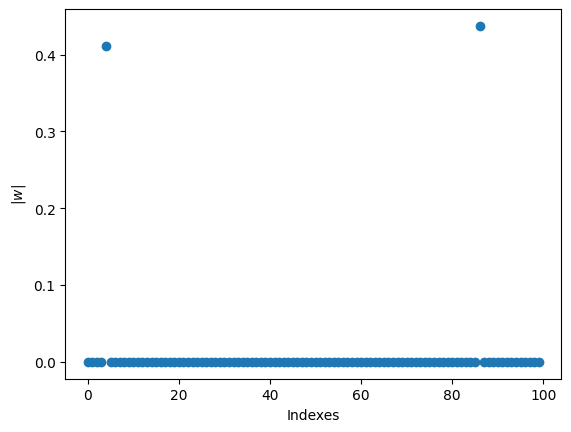

In [35]:
# Data standardization
mean = np.mean(Xtr, axis=0)
std = np.std(Xtr, axis=0)

Xtrnorm = np.divide((Xtr-mean), std)
Xtenorm = np.divide((Xte-mean), std)

# Run Orthogonal Matching Pursuit with `iters` iterations
iters = 2 # = al numero di feature importanti che voglio selezionare
w, r, I = OMP(Xtrnorm, Ytr, iters)

print(f'I: {I}')

# Compute the prediction on the test set
Ypred = np.sign(Xtenorm.dot(w))

# Compute the test error and show its value
te_err = calcError(Yte, Ypred)
print(f'Test Error : {te_err}%')

# Plot the components of the solution w
plt.scatter(np.arange(d), abs(w))

plt.xlabel('Indexes')
plt.ylabel(r'$|w|$')

## K-fold cross validation

Until now, we have defined the number of iterations `iters` of the Orthogonal Matching Pursuit algorithm _manually_. We will now use K-Fold cross validation to automatically select the best number of iterations for the OMP algorithm.

We will use a function with the following signature:
    
`bestniter, Vm, Vs, Tm, Ts = KFoldCVOMP(Xtr, Ytr, KF, niter_list)`

where:

*   `Xtr`: training input data
*   `Ytr`: training output labels
*   `KF`: number of folds
*   `niter_list`: list of iteration counters on which perform cross validation


*   `bestniter`: best iteration counter leading to the minimum error on the validation set
*   `Vm`, `Vs`, `Tm`, `Ts`: lists containing the means and the standard deviations on the k-folds foe each iteration counter in `niter_list`, both for the validation (V) and training (T) sets


In [9]:
def KFoldCVOMP(Xtr, Ytr, KF, niter_list):
    # Ensures that k_list is a numpy array
    niter_list = np.array(niter_list)
    num_niter = niter_list.size

    n_tot = Xtr.shape[0]
    n_val = int(np.floor(n_tot/KF))

    Tm = np.zeros(num_niter)
    Ts = np.zeros(num_niter)
    Vm = np.zeros(num_niter)
    Vs = np.zeros(num_niter)

    # Random permutation of training data
    rand_idx = np.random.choice(n_tot, size=n_tot, replace=False)

    for kdx, niter in enumerate(niter_list):
        first = 0
        for fold in range(KF):
            flags = np.zeros(Xtr.shape[0])
            flags[first:first+n_val]=1;

            X = Xtr[rand_idx[flags==0]]
            Y = Ytr[rand_idx[flags==0]]
            X_val = Xtr[rand_idx[flags==1]]
            Y_val = Ytr[rand_idx[flags==1]]

            # Compute the training error of OMP for the given number of iterations
            w, r, I = OMP(X, Y, niter)
            YpredTR = np.sign(X.dot(w))
            trError = calcError(YpredTR, Y)
            Tm[kdx] = Tm[kdx] + trError
            Ts[kdx] = Ts[kdx] + trError ** 2

            # Compute the validation error OMP for the given number of iterations
            YpredVAL = np.sign(X_val.dot(w))
            valError = calcError(YpredVAL, Y_val)
            Vm[kdx] = Vm[kdx] + valError
            Vs[kdx] = Vs[kdx] + valError ** 2

            first = first+n_val

    Tm = Tm / KF
    Ts = Ts / KF - Tm ** 2

    Vm = Vm / KF
    Vs = Vs / KF - Vm ** 2

    best_niter_idx = np.argmin(Vm)
    bestniter = niter_list[best_niter_idx]

    print(Vm)
    print(niter_list)
    print(best_niter_idx)

    return bestniter, Vm, Vs, Tm, Ts

Now run the `KFoldCVOMP()` function to find the best number of iterations:

[11.35  4.05  4.2   4.3   4.2   4.6   4.6 ]
[ 1  2  3  4  5 10 30]
1
Best number of iterations: 2


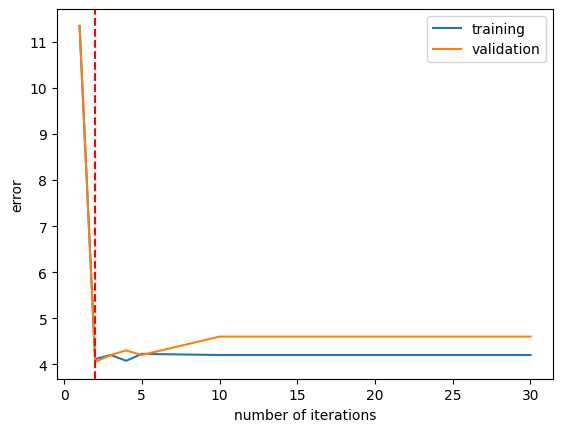

In [10]:
# Define an appropriate range of possible iterations number and run K-Fold Cross Validation
KF = 5
niter_list = [1, 2, 3, 4, 5, 10, d]
bestniter, Vm, Vs, Tm, Ts = KFoldCVOMP(Xtrnorm, Ytr, KF, niter_list)

# Plot training and validation error
plt.subplots()
plt.plot(niter_list, Tm, label="training")
plt.plot(niter_list, Vm, label="validation")

plt.legend(loc="best")
plt.xlabel("number of iterations")
plt.ylabel('error')
plt.axvline(bestniter, color="red", ls='--')

print(f'Best number of iterations: {bestniter}')

We can also shuffle the columns of the dataset in order to better observe the behavior of OMP:

In [17]:
shuffle_idx = np.random.choice(Xtr.shape[1], Xtr.shape[1], replace=False)

Xtr = Xtr[:, shuffle_idx]
Xte = Xte[:, shuffle_idx]

print(f'The relevant features are {np.argmax(shuffle_idx == 0)} and {np.argmax(shuffle_idx == 1)}')

The relevant features are 7 and 12


I: [44, 58]


Text(0, 0.5, '$|w|$')

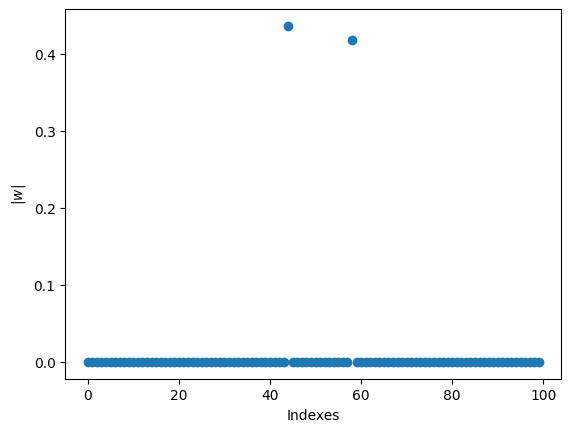

In [18]:
# Data standardization
mean = np.mean(Xtr, axis=0)
std = np.std(Xtr, axis=0)

Xtrnorm = np.divide((Xtr-mean), std)
Xtenorm = np.divide((Xte-mean), std)

# Run Orthogonal Matching Pursuit
w, r, I = OMP(Xtrnorm, Ytr, 2)

print(f'I: {I}')

# Plot the components of the solution w
plt.scatter(np.arange(d), abs(w))
plt.xlabel('Indexes')
plt.ylabel(r'$|w|$')

Try to increase the number of relevant and dummy features and observe the behavior of OMP:

In [39]:
n = 2000
d = 100
d_rev = 20

m1 = [2 for d in range(d_rev)]
m2 = [1 for d in range(1, 1 + d_rev)]

Xtr, Ytr = mixGauss(means = [m1,m2], sigmas = [0.9, 0.75], n=n)
Xte, Yte = mixGauss(means = [m1,m2], sigmas = [0.9, 0.75], n=n)
print(Xtr.shape)

(4000, 20)


In [40]:
# dummy features generation
sigma_noise = 0.13
Xtr_noise = sigma_noise * np.random.randn(2*n, d-d_rev)
Xtr = np.concatenate((Xtr,Xtr_noise), axis=1)
Xte_noise = sigma_noise * np.random.randn(2*n, d-d_rev)
Xte = np.concatenate((Xte,Xte_noise), axis=1)

shuffle_idx = np.random.choice(Xtr.shape[1], Xtr.shape[1], replace=False)
Xtr = Xtr[:, shuffle_idx]
Xte = Xte[:, shuffle_idx]

I: [69, 78, 1, 6, 60, 48, 21, 44, 30, 15, 92, 94]
Test Error : 1.7999999999999998%


Text(0, 0.5, 'w')

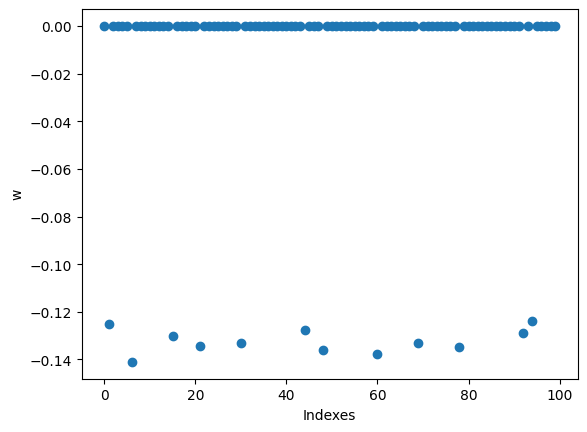

In [43]:
# Data standardization
mean = np.mean(Xtr, axis=0)
std = np.std(Xtr, axis=0)

Xtrnorm = np.divide((Xtr-mean), std)
Xtenorm = np.divide((Xte-mean), std)

# Run Orthogonal Matching Pursuit
w, r, I = OMP(Xtrnorm, Ytr, 12)

print(f'I: {I}')

# Compute the prediction on the test set
Ypred = np.sign(Xtenorm.dot(w))

# Compute the test error and show its value
te_err = calcError(Yte, Ypred)
print(f'Test Error : {te_err}%')

# Plot the components of the solution w
plt.scatter(np.arange(d), abs(w))
plt.xlabel('Indexes')
plt.ylabel(r'$|w|$')